# CreditParity – Step 5
**BUS/FIN 241A · Final Team Project · Profitable, Fair Lending Decisions**

**Step 5:** Threshold optimization and the three-zone decision policy

## Step 5 · Threshold Optimization and Decision Policy

**Goal.** Step 4 settled the model (logistic regression). Now we decide *what to do* with its default probability:
- **a)** Find the cost-optimal single threshold and compare it with the default threshold of 0.5.
- **b)** Turn it into a three-zone human-in-the-loop policy: 🟢 auto-approve, 🟡 manual review, 🔴 decline recommended.
- **c)** Choose every threshold with **cross-validation on the training set** and use the test set **only once**, for the final evaluation.

**How we avoid overfitting the thresholds.** We create *out-of-fold* predictions for the 4,000 training applications: each application is scored by a model trained on the other four folds (5-fold stratified CV, the same folds as in Step 4). These predictions behave like predictions on new data, so we can tune thresholds on them without touching the test set.

**Assumptions** (all can be changed; the dashboard in Step 9 lets the bank explore them):

| Assumption | Value | Meaning |
|---|---|---|
| Cost of a missed default (FN) | 5 | Bank loses a large part of the loan |
| Cost of a rejected good customer (FP) | 1 | Bank loses the interest margin |
| Cost of one manual review | 0.2 | Analyst time, as a share of one lost margin |
| Analyst improvement | 50% | On a reviewed case, the analyst avoids half of the errors the model would make, thanks to extra information (documents, conversation) |
| Analyst capacity | 30% | At most 30% of all applications can go to manual review |

The 5:1 ratio is the classic assumption for this dataset; the review cost, analyst improvement and capacity are our own assumptions. We test how sensitive the result is to them.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, confusion_matrix

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}

# Cost assumptions (see table above)
COST_FN = 5            # missed default
COST_FP = 1            # rejected good customer
COST_REVIEW = 0.2      # one manual review
ANALYST_GAIN = 0.5     # share of model errors the analyst avoids on reviewed cases
MAX_REVIEW_SHARE = 0.30

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 and 4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Final model from Step 4: logistic regression with default settings
def make_model():
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
            ("num", StandardScaler(), numeric)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

# Out-of-fold default probabilities for the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
p_oof = cross_val_predict(make_model(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
y_oof = y_train.to_numpy()
fold_id = np.empty(len(y_oof), dtype=int)
for k, (_, val_idx) in enumerate(cv.split(X_train, y_train)):
    fold_id[val_idx] = k
print("Out-of-fold predictions:", len(p_oof), "| mean predicted PD:", round(p_oof.mean(), 3),
      "| observed default rate:", round(y_oof.mean(), 3))

Out-of-fold predictions: 4000 | mean predicted PD: 0.335 | observed default rate: 0.334


### a) The cost-optimal single threshold

With a single threshold *t*, every application with a default probability ≥ *t* is declined. The total cost is

$$\text{Cost}(t) = 5 \cdot \text{FN}(t) + 1 \cdot \text{FP}(t).$$

If the probabilities were perfectly calibrated, theory says the optimum is $t^* = \frac{1}{1+5} \approx 0.17$: decline as soon as the expected loss of approving (5 · PD) exceeds the expected loss of declining (1 · (1 − PD)). We search the actual optimum on a grid of thresholds.

In [3]:
THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def single_threshold_metrics(p, y_true, t):
    """Decline if p >= t. Returns cost and standard metrics."""
    decline = p >= t
    fn = int(((~decline) & (y_true == 1)).sum())
    fp = int((decline & (y_true == 0)).sum())
    return {"Threshold": t,
            "Cost": COST_FN * fn + COST_FP * fp,
            "Cost per 100 applications": 100 * (COST_FN * fn + COST_FP * fp) / len(y_true),
            "Recall": recall_score(y_true, decline),
            "Precision": precision_score(y_true, decline, zero_division=0),
            "Approval rate": 1 - decline.mean(),
            "FN": fn, "FP": fp}

cost_curve = pd.DataFrame([single_threshold_metrics(p_oof, y_oof, t) for t in THRESHOLDS])
T_OPT = float(cost_curve.loc[cost_curve["Cost"].idxmin(), "Threshold"])
near_opt = cost_curve.loc[cost_curve["Cost"] <= 1.02 * cost_curve["Cost"].min(), "Threshold"]
print(f"Cost-optimal threshold (out-of-fold): {T_OPT}")
print(f"Thresholds within 2% of the minimum cost: {near_opt.min()} to {near_opt.max()}")

Cost-optimal threshold (out-of-fold): 0.11
Thresholds within 2% of the minimum cost: 0.09 to 0.14


In [4]:
# Is the optimum stable across folds?
fold_opt = []
for k in range(5):
    m = fold_id == k
    costs = [single_threshold_metrics(p_oof[m], y_oof[m], t)["Cost"] for t in THRESHOLDS]
    fold_opt.append({"Fold": k + 1, "Optimal threshold": THRESHOLDS[int(np.argmin(costs))]})
pd.DataFrame(fold_opt).set_index("Fold").T

Fold,1,2,3,4,5
Optimal threshold,0.14,0.09,0.14,0.14,0.14


In [5]:
# Compare: default 0.5, theoretical 1/6, cost-optimal
compare_single = pd.DataFrame([single_threshold_metrics(p_oof, y_oof, t)
                               for t in [0.5, round(1 / 6, 2), T_OPT]])
compare_single.insert(0, "Rule", ["Default (0.5)", "Theoretical (1/6)", "Cost-optimal (CV)"])
compare_single.set_index("Rule").round(3)

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
Default (0.5),0.50,2865,71.625,0.616,0.733,0.719,513,300
Theoretical (1/6),0.17,1878,46.950,0.891,0.509,0.416,146,1148
Cost-optimal (CV),0.11,1762,44.050,0.952,0.469,0.322,64,1442


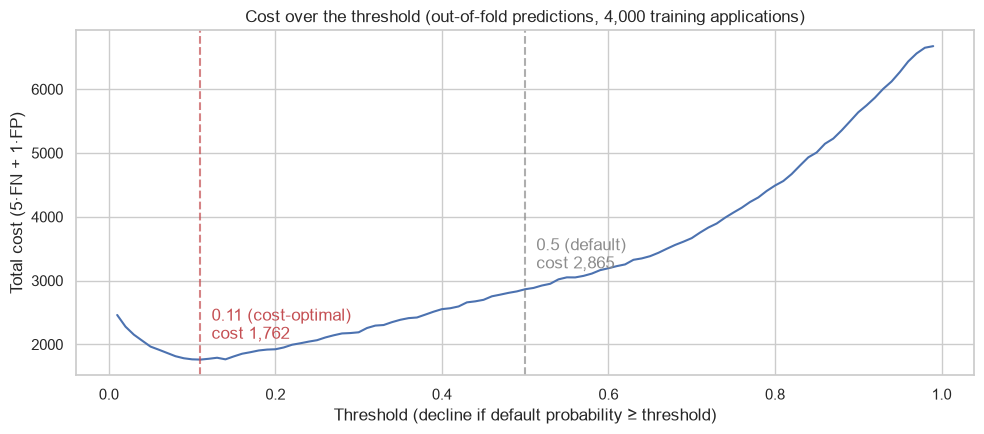

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(cost_curve["Threshold"], cost_curve["Cost"], color="#4C72B0")
for t, label, color in [(0.5, "0.5 (default)", "#8C8C8C"),
                        (T_OPT, f"{T_OPT} (cost-optimal)", "#C44E52")]:
    c = cost_curve.loc[cost_curve["Threshold"] == t, "Cost"].iloc[0]
    ax.axvline(t, ls="--", color=color, alpha=0.7)
    ax.annotate(f"{label}\ncost {c:,.0f}", (t, c), xytext=(8, 15),
                textcoords="offset points", color=color)
ax.set_xlabel("Threshold (decline if default probability ≥ threshold)")
ax.set_ylabel("Total cost (5·FN + 1·FP)")
ax.set_title("Cost over the threshold (out-of-fold predictions, 4,000 training applications)")
plt.tight_layout()
plt.show()

In [7]:
# Why is the optimum below the theoretical 1/6? Check calibration by probability band
bands = pd.cut(p_oof, [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0])
pd.DataFrame({"p": p_oof, "y": y_oof}).groupby(bands, observed=True).agg(
    Applications=("y", "size"), Mean_predicted_PD=("p", "mean"),
    Observed_default_rate=("y", "mean")).round(3)

,Applications,Mean_predicted_PD,Observed_default_rate
"(0.0, 0.05]",770,0.022,0.016
"(0.05, 0.1]",446,0.074,0.092
"(0.1, 0.2]",598,0.148,0.211
"(0.2, 0.3]",436,0.248,0.268
"(0.3, 0.4]",339,0.350,0.345
"(0.4, 0.6]",505,0.490,0.378
"(0.6, 0.8]",432,0.703,0.667
"(0.8, 1.0]",474,0.893,0.937


**Result (a).** On the out-of-fold predictions, the cost-optimal threshold is **0.11**. It cuts the total cost from **2,865 to 1,762 (−38%)** compared with the default threshold of 0.5:

| Rule (out-of-fold, 4,000 applications) | Threshold | Cost | Recall | Precision | Approval rate |
|---|---|---|---|---|---|
| Default | 0.50 | 2,865 | 0.616 | 0.733 | 71.9% |
| Theoretical (1/6) | 0.17 | 1,878 | 0.891 | 0.509 | 41.6% |
| **Cost-optimal (CV)** | **0.11** | **1,762** | **0.952** | 0.469 | 32.2% |

- **The price of catching defaults.** Recall rises from 62% to 95%: only 64 of 1,336 defaults slip through instead of 513. In return, many more good customers are declined (1,442 instead of 300), and only about a third of applications would be approved. This is exactly where a human should step in (part b).
- **Stable choice.** The cost curve is flat around its minimum: every threshold between 0.09 and 0.14 is within 2% of the lowest cost. The per-fold optimum is 0.14 in four folds and 0.09 in one.
- **Why below 1/6?** The calibration table shows that the model *underestimates* risk in the 0.1–0.2 band (predicted 15%, observed 21%). Applications with a predicted PD of 0.11–0.17 are therefore riskier than they look, and declining them pays off. The threshold search picks this up automatically, which is one reason to tune the threshold on data rather than to rely on the formula alone.

### b) The three-zone policy

Two thresholds split the applications into three zones:

| Zone | Rule | What happens | Cost |
|---|---|---|---|
| 🟢 Green | PD < lower boundary | Auto-approve | 5 per default that slips through |
| 🟡 Yellow | lower ≤ PD < upper | Manual review by a credit analyst | 0.2 per review + the remaining errors |
| 🔴 Red | PD ≥ upper boundary | Decline recommended (human makes the final call) | 1 per good customer declined |

**Cost of the yellow zone.** Without extra information, the analyst would decide like the model at the cost-optimal threshold. We assume the analyst avoids 50% of these errors thanks to documents and a conversation with the applicant. So a reviewed case costs 0.2 plus half of the error cost the cost-optimal threshold would cause.

**Choosing the boundaries.** We try every pair of boundaries on a grid of 0.01 and keep the cheapest one whose manual review share stays within analyst capacity (30%).

In [8]:
def zone_of(p, lower, upper):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

def zone_table(p, y_true, lower, upper, t_opt=T_OPT,
               cost_review=COST_REVIEW, analyst_gain=ANALYST_GAIN):
    """Per-zone counts and costs for one pair of boundaries."""
    zone = zone_of(p, lower, upper)
    rows = []
    for z in ["Green", "Yellow", "Red"]:
        m = zone == z
        defaults = int((m & (y_true == 1)).sum())
        goods = int((m & (y_true == 0)).sum())
        if z == "Green":
            cost = COST_FN * defaults
        elif z == "Red":
            cost = COST_FP * goods
        else:
            # errors the cost-optimal threshold would make on these cases
            model_errors = (COST_FN * (m & (p < t_opt) & (y_true == 1)).sum()
                            + COST_FP * (m & (p >= t_opt) & (y_true == 0)).sum())
            cost = cost_review * m.sum() + (1 - analyst_gain) * model_errors
        rows.append({"Zone": z, "Applications": int(m.sum()), "Share": m.mean(),
                     "Defaults": defaults, "Good customers": goods,
                     "Default rate": defaults / max(m.sum(), 1), "Cost": cost})
    table = pd.DataFrame(rows).set_index("Zone")
    table.loc["Total"] = [table["Applications"].sum(), 1.0, table["Defaults"].sum(),
                          table["Good customers"].sum(), y_true.mean(), table["Cost"].sum()]
    return table

def zone_summary(p, y_true, lower, upper, **kw):
    """One-line summary: total cost, review workload and how many defaults are kept out of auto-approval."""
    t = zone_table(p, y_true, lower, upper, **kw)
    zone = zone_of(p, lower, upper)
    return {"Lower": lower, "Upper": upper, "Cost": t.loc["Total", "Cost"],
            "Cost per 100 applications": 100 * t.loc["Total", "Cost"] / len(y_true),
            "Auto-approved": t.loc["Green", "Share"], "Manual review": t.loc["Yellow", "Share"],
            "Decline recommended": t.loc["Red", "Share"],
            "Defaults not auto-approved": 1 - t.loc["Green", "Defaults"] / max((y_true == 1).sum(), 1),
            "Default rate in green": t.loc["Green", "Default rate"],
            "Precision of red": 1 - t.loc["Red", "Good customers"] / max(t.loc["Red", "Applications"], 1)}

def zone_cost(p, y_true, lower, upper, t_opt=T_OPT,
              cost_review=COST_REVIEW, analyst_gain=ANALYST_GAIN):
    """Fast total cost of a pair of boundaries (same logic as zone_table)."""
    green, red = p < lower, p >= upper
    yellow = ~green & ~red
    model_errors = (COST_FN * (yellow & (p < t_opt) & (y_true == 1)).sum()
                    + COST_FP * (yellow & (p >= t_opt) & (y_true == 0)).sum())
    return (COST_FN * (green & (y_true == 1)).sum() + COST_FP * (red & (y_true == 0)).sum()
            + cost_review * yellow.sum() + (1 - analyst_gain) * model_errors)

def search_zones(p, y_true, max_review_share, **kw):
    """Cheapest pair of boundaries whose manual review share stays within capacity."""
    best_cost, best_pair = np.inf, None
    for lower in THRESHOLDS:
        for upper in THRESHOLDS[THRESHOLDS >= lower]:
            if ((p >= lower) & (p < upper)).mean() > max_review_share + 1e-9:
                break   # a higher upper boundary only adds more reviews
            c = zone_cost(p, y_true, lower, upper, **kw)
            if c < best_cost - 1e-9:
                best_cost, best_pair = c, (float(lower), float(upper))
    return zone_summary(p, y_true, *best_pair, **kw)

best = search_zones(p_oof, y_oof, MAX_REVIEW_SHARE)
T_LOWER, T_UPPER = float(best["Lower"]), float(best["Upper"])
print(f"Chosen zone boundaries: green < {T_LOWER} ≤ yellow < {T_UPPER} ≤ red")
zone_table(p_oof, y_oof, T_LOWER, T_UPPER).round(3)

Chosen zone boundaries: green < 0.11 ≤ yellow < 0.37 ≤ red


,Applications,Share,Defaults,Good customers,Default rate,Cost
Zone,,,,,,
Green,1286,0.322,64,1222,0.050,320.0
Yellow,1200,0.300,310,890,0.258,685.0
Red,1514,0.378,962,552,0.635,552.0
Total,4000,1.000,1336,2664,0.334,1557.0


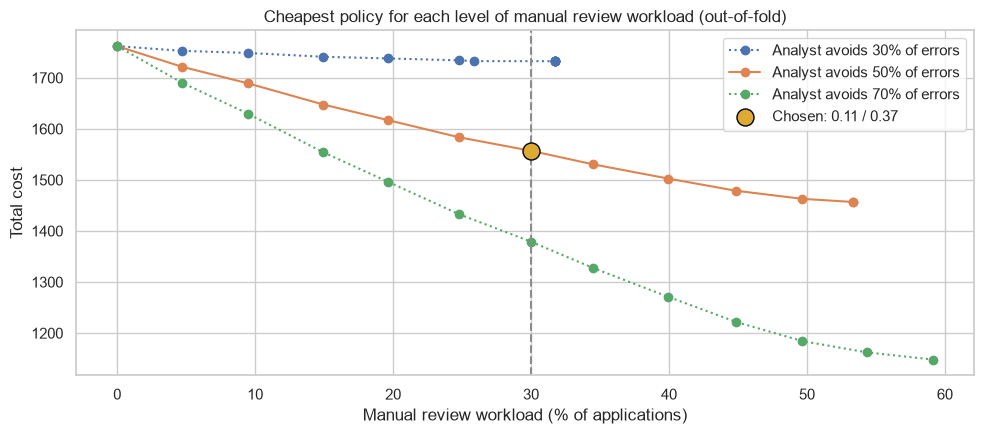

,Lower,Upper,Cost,Manual review,Defaults not auto-approved
Capacity,,,,,
0.00,0.11,0.11,1762.0,0.000,0.952
0.05,0.11,0.14,1721.6,0.047,0.952
0.10,0.10,0.16,1689.0,0.095,0.960
0.15,0.10,0.20,1647.6,0.150,0.960
0.20,0.10,0.24,1617.3,0.196,0.960
0.25,0.10,0.29,1583.4,0.248,0.960
0.30,0.11,0.37,1557.0,0.300,0.952
0.35,0.09,0.38,1530.5,0.345,0.968
0.40,0.09,0.45,1502.6,0.400,0.968


In [9]:
# Trade-off between cost and manual review workload
capacities = np.round(np.arange(0.0, 0.61, 0.05), 2)
frontier = []
for gain in [0.3, 0.5, 0.7]:
    for cap in capacities:
        s = search_zones(p_oof, y_oof, cap, analyst_gain=gain)
        frontier.append({"Analyst improvement": gain, "Capacity": cap, **s})
frontier = pd.DataFrame(frontier)

fig, ax = plt.subplots(figsize=(10, 4.5))
for gain, grp in frontier.groupby("Analyst improvement"):
    style = "-" if gain == ANALYST_GAIN else ":"
    ax.plot(100 * grp["Manual review"], grp["Cost"], style, marker="o",
            label=f"Analyst avoids {int(gain * 100)}% of errors")
ax.axvline(100 * MAX_REVIEW_SHARE, ls="--", color="#8C8C8C")
ax.scatter([100 * best["Manual review"]], [best["Cost"]], s=150, color="#DDAA33",
           zorder=5, edgecolor="black", label=f"Chosen: {T_LOWER} / {T_UPPER}")
ax.set_xlabel("Manual review workload (% of applications)")
ax.set_ylabel("Total cost")
ax.set_title("Cheapest policy for each level of manual review workload (out-of-fold)")
ax.legend()
plt.tight_layout()
plt.show()

frontier[frontier["Analyst improvement"] == ANALYST_GAIN][
    ["Capacity", "Lower", "Upper", "Cost", "Manual review", "Defaults not auto-approved"]
].set_index("Capacity").round(3)

In [10]:
# Sensitivity: how do the chosen boundaries react to the assumptions?
sens = []
for cost_review in [0.1, 0.2, 0.3]:
    for gain in [0.3, 0.5, 0.7]:
        for cap in [0.2, 0.3, 0.4]:
            s = search_zones(p_oof, y_oof, cap, cost_review=cost_review, analyst_gain=gain)
            sens.append({"Review cost": cost_review, "Analyst improvement": gain, "Capacity": cap,
                         "Lower": s["Lower"], "Upper": s["Upper"],
                         "Manual review": round(s["Manual review"], 3)})
sens = pd.DataFrame(sens)
sens.pivot_table(index=["Review cost", "Analyst improvement"], columns="Capacity",
                 values=["Lower", "Upper"])

Lower             Upper            
Capacity                          0.2   0.3   0.4   0.2   0.3   0.4
Review cost Analyst improvement                                    
0.1         0.3                  0.10  0.11  0.09  0.24  0.37  0.45
            0.5                  0.10  0.11  0.09  0.24  0.37  0.45
            0.7                  0.10  0.11  0.09  0.24  0.37  0.45
0.2         0.3                  0.10  0.10  0.10  0.24  0.30  0.37
            0.5                  0.10  0.11  0.09  0.24  0.37  0.45
            0.7                  0.10  0.11  0.09  0.24  0.37  0.45
0.3         0.3                  0.11  0.11  0.11  0.11  0.11  0.11
            0.5                  0.10  0.09  0.09  0.24  0.30  0.45
            0.7                  0.10  0.11  0.09  0.24  0.37  0.45

In [11]:
# Stability across folds: search the boundaries on each fold separately
fold_zones = []
for k in range(5):
    m = fold_id == k
    s = search_zones(p_oof[m], y_oof[m], MAX_REVIEW_SHARE)
    fold_zones.append({"Fold": k + 1, "Lower": s["Lower"], "Upper": s["Upper"],
                       "Manual review": round(s["Manual review"], 3)})
pd.DataFrame(fold_zones).set_index("Fold").T

Fold,1,2,3,4,5
Lower,0.140,0.090,0.100,0.060,0.100
Upper,0.420,0.320,0.340,0.250,0.350
Manual review,0.286,0.298,0.296,0.295,0.299


In [12]:
# All policies side by side on the out-of-fold predictions
def single_as_policy(p, y_true, t):
    s = single_threshold_metrics(p, y_true, t)
    return {"Cost": s["Cost"], "Cost per 100 applications": s["Cost per 100 applications"],
            "Auto-approved": s["Approval rate"], "Manual review": 0.0,
            "Decline recommended": 1 - s["Approval rate"], "Defaults not auto-approved": s["Recall"]}

def policy_comparison(p, y_true):
    rows = {
        "Single threshold 0.5": single_as_policy(p, y_true, 0.5),
        f"Single threshold {T_OPT} (cost-optimal)": single_as_policy(p, y_true, T_OPT),
        "Zones 0.2 / 0.6 (preliminary)": zone_summary(p, y_true, 0.2, 0.6),
        f"Zones {T_LOWER} / {T_UPPER} (chosen)": zone_summary(p, y_true, T_LOWER, T_UPPER),
    }
    cols = ["Cost", "Cost per 100 applications", "Auto-approved", "Manual review",
            "Decline recommended", "Defaults not auto-approved"]
    return pd.DataFrame(rows).T[cols].astype(float)

policy_comparison(p_oof, y_oof).round(3)

,Cost,Cost per 100 applications,Auto-approved,Manual review,Decline recommended,Defaults not auto-approved
Single threshold 0.5,2865.0,71.625,0.719,0.00,0.281,0.616
Single threshold 0.11 (cost-optimal),1762.0,44.050,0.322,0.00,0.678,0.952
Zones 0.2 / 0.6 (preliminary),1752.5,43.812,0.454,0.32,0.226,0.866
Zones 0.11 / 0.37 (chosen),1557.0,38.925,0.322,0.30,0.378,0.952


**Result (b).** The chosen boundaries are **0.11 and 0.37**:

| Zone (out-of-fold) | Share | Defaults | Good customers | Default rate | Cost |
|---|---|---|---|---|---|
| 🟢 Green (PD < 0.11) | 32.2% | 64 | 1,222 | 5.0% | 320 |
| 🟡 Yellow (0.11 – 0.37) | 30.0% | 310 | 890 | 25.8% | 685 |
| 🔴 Red (PD ≥ 0.37) | 37.8% | 962 | 552 | 63.5% | 552 |
| **Total** | | 1,336 | 2,664 | 33.4% | **1,557** |

- **The lower boundary is the cost-optimal threshold.** Every application the single threshold of 0.11 would approve is still approved automatically, so the policy keeps a recall of 95%: only 64 of 1,336 defaults are auto-approved.
- **The yellow zone is where good customers are won back.** Three out of four yellow applications are good customers that the single threshold would decline. An analyst who knows more than the model can approve many of them. Under our assumptions this lowers the cost from 1,762 to **1,557 (−12% compared with the single threshold, −46% compared with 0.5)**.
- **The trade-off.** More review capacity lowers the cost, but with diminishing returns (see the plot). If the analysts avoid only 30% of errors, manual review hardly pays off; at 70% it pays off strongly. *Without* any analyst improvement, the zones would cost more than the single threshold, because the reviews themselves cost time. The value of the yellow zone therefore depends on the analysts' added information, which we cannot measure with this dataset.
- **Robustness.** The lower boundary stays between 0.09 and 0.11 across all assumption settings. In one setting (review cost 0.3, analyst improvement 30%) reviews do not pay off at all, and the search drops the yellow zone (both boundaries at 0.11). The upper boundary is mainly set by the analyst capacity (0.24 at 20%, 0.37 at 30%, 0.45 at 40%). Searching each fold separately gives lower boundaries of 0.06–0.14 and upper boundaries of 0.25–0.42, so the exact values carry some uncertainty, which the dashboard sliders make visible.
- **Compared with the preliminary zones 0.2 / 0.6.** These auto-approved more applications (45%), but also let more defaults through (13% of all defaults instead of 5%), and cost 1,753 instead of 1,557.

### c) Final evaluation on the test set

Now – and only now – we use the test set. We train the logistic regression on all 4,000 training applications and apply the thresholds chosen above **without any change** to the 1,000 test applications.

In [13]:
final_model = make_model().fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
y_test_arr = y_test.to_numpy()

test_single = pd.DataFrame([single_threshold_metrics(p_test, y_test_arr, t) for t in [0.5, T_OPT]])
test_single.insert(0, "Rule", ["Default (0.5)", f"Cost-optimal ({T_OPT})"])
display(test_single.set_index("Rule").round(3))

for t in [0.5, T_OPT]:
    tn, fp, fn, tp = confusion_matrix(y_test_arr, (p_test >= t).astype(int)).ravel()
    print(f"Threshold {t}: TP {tp}, TN {tn}, FP {fp}, FN {fn}")

,Threshold,Cost,Cost per 100 applications,Recall,Precision,Approval rate,FN,FP
Rule,,,,,,,,
Default (0.5),0.50,700,70.0,0.626,0.736,0.716,125,75
Cost-optimal (0.11),0.11,409,40.9,0.958,0.486,0.341,14,339


Threshold 0.5: TP 209, TN 591, FP 75, FN 125
Threshold 0.11: TP 320, TN 327, FP 339, FN 14


In [14]:
print(f"Test set – zones {T_LOWER} / {T_UPPER}")
test_zones = zone_table(p_test, y_test_arr, T_LOWER, T_UPPER)
display(test_zones.round(3))
policy_comparison(p_test, y_test_arr).round(3)

Test set – zones 0.11 / 0.37


,Applications,Share,Defaults,Good customers,Default rate,Cost
Zone,,,,,,
Green,341,0.341,14,327,0.041,70.0
Yellow,273,0.273,75,198,0.275,153.6
Red,386,0.386,245,141,0.635,141.0
Total,1000,1.000,334,666,0.334,364.6


,Cost,Cost per 100 applications,Auto-approved,Manual review,Decline recommended,Defaults not auto-approved
Single threshold 0.5,700.0,70.00,0.716,0.000,0.284,0.626
Single threshold 0.11 (cost-optimal),409.0,40.90,0.341,0.000,0.659,0.958
Zones 0.2 / 0.6 (preliminary),392.0,39.20,0.454,0.320,0.226,0.889
Zones 0.11 / 0.37 (chosen),364.6,36.46,0.341,0.273,0.386,0.958


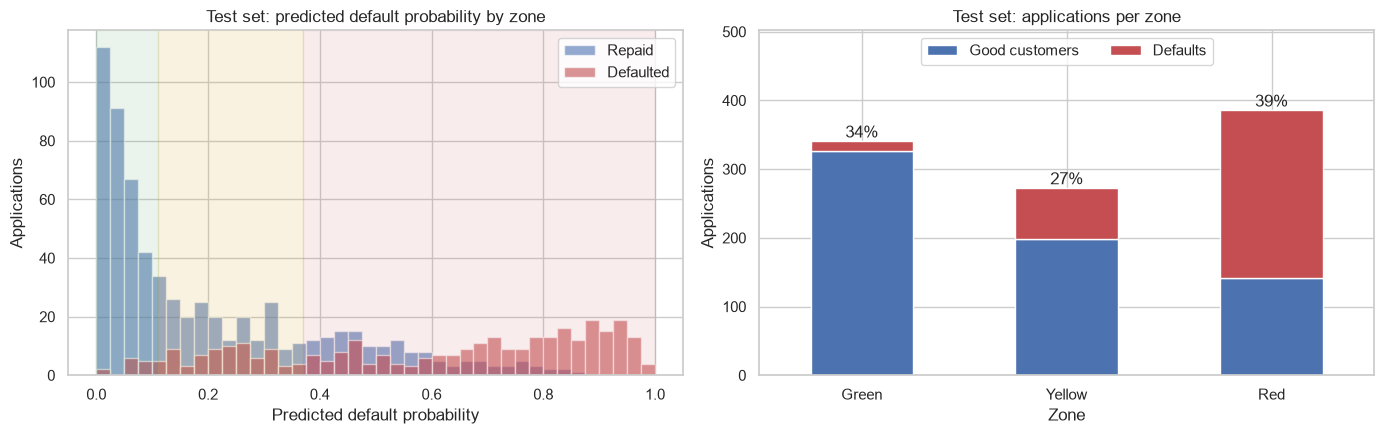

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: distribution of default probabilities with the zone boundaries
bins = np.linspace(0, 1, 41)
axes[0].hist(p_test[y_test_arr == 0], bins=bins, alpha=0.6, label="Repaid", color="#4C72B0")
axes[0].hist(p_test[y_test_arr == 1], bins=bins, alpha=0.6, label="Defaulted", color="#C44E52")
axes[0].axvspan(0, T_LOWER, color=ZONE_COLORS["Green"], alpha=0.12)
axes[0].axvspan(T_LOWER, T_UPPER, color=ZONE_COLORS["Yellow"], alpha=0.15)
axes[0].axvspan(T_UPPER, 1, color=ZONE_COLORS["Red"], alpha=0.10)
axes[0].set_xlabel("Predicted default probability")
axes[0].set_ylabel("Applications")
axes[0].set_title("Test set: predicted default probability by zone")
axes[0].legend()

# Right: composition of each zone
comp = test_zones.loc[["Green", "Yellow", "Red"], ["Good customers", "Defaults"]]
comp.plot.bar(stacked=True, color=["#4C72B0", "#C44E52"], ax=axes[1], rot=0)
axes[1].set_ylim(0, comp.sum(axis=1).max() * 1.3)
axes[1].legend(loc="upper center", ncol=2)
for i, z in enumerate(comp.index):
    axes[1].text(i, comp.loc[z].sum() + 5, f"{test_zones.loc[z, 'Share']:.0%}", ha="center")
axes[1].set_title("Test set: applications per zone")
axes[1].set_ylabel("Applications")
plt.tight_layout()
plt.show()

**Result (c) – final evaluation on the test set.** The thresholds chosen on the training data carry over to the 1,000 unseen test applications:

| Policy (test set) | Cost | Auto-approved | Manual review | Decline recommended | Defaults not auto-approved |
|---|---|---|---|---|---|
| Single threshold 0.5 | 700 | 71.6% | – | 28.4% | 62.6% |
| Single threshold 0.11 | 409 (−42%) | 34.1% | – | 65.9% | 95.8% |
| **Zones 0.11 / 0.37** | **364.6 (−48%)** | 34.1% | 27.3% | 38.6% | 95.8% |

- At the threshold of 0.11, recall rises from **0.626 to 0.958** (TP 320, FN 14 instead of TP 209, FN 125). Precision falls from 0.736 to 0.486, as FP rises from 75 to 339.
- The three zones on the test set: green 34.1% (default rate 4.1%), yellow 27.3% (default rate 27.5%), red 38.6% (default rate 63.5%). The manual review share stays within the 30% capacity.
- Test costs per 100 applications (70.0 / 40.9 / 36.5) are close to the out-of-fold values (71.6 / 44.1 / 38.9), so the thresholds were not overfitted.

**Decision for CreditParity.** We use the logistic regression with the zone boundaries **0.11 (green / yellow)** and **0.37 (yellow / red)**. The cost-optimal single threshold 0.11 is kept as the reference point for the analyst cost model.

**Limitations.**
- The 5:1 cost ratio, the review cost, the analyst improvement and the capacity are **assumptions**. The cost savings of the yellow zone in particular rest on the assumed analyst improvement, which this dataset cannot measure.
- In the red zone the human makes the final call; our cost model assumes the recommendation is followed.
- The dataset is synthetic. The strong separation between defaults and good customers may be larger than in real loan data.
- The thresholds have not yet been checked for fairness. Step 6 tests whether some groups land in the yellow or red zone disproportionately often.

**Next step.** Step 6: fairness by Sex, age group and ForeignWorker, for the model and per zone.